<a href="https://colab.research.google.com/github/poojagupthaa14/OIBSIP/blob/main/pooja_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

uploaded = files.upload()

Saving Tweets.csv to Tweets.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('Tweets.csv')

In [4]:
df.head()

,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


In [5]:
df.shape

(14640, 15)

In [6]:
df.columns

Index(['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence',
       'negativereason', 'negativereason_confidence', 'airline',
       'airline_sentiment_gold', 'name', 'negativereason_gold',
       'retweet_count', 'text', 'tweet_coord', 'tweet_created',
       'tweet_location', 'user_timezone'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   tweet_id                      14640 non-null  int64  
 1   airline_sentiment             14640 non-null  object 
 2   airline_sentiment_confidence  14640 non-null  float64
 3   negativereason                9178 non-null   object 
 4   negativereason_confidence     10522 non-null  float64
 5   airline                       14640 non-null  object 
 6   airline_sentiment_gold        40 non-null     object 
 7   name                          14640 non-null  object 
 8   negativereason_gold           32 non-null     object 
 9   retweet_count                 14640 non-null  int64  
 10  text                          14640 non-null  object 
 11  tweet_coord                   1019 non-null   object 
 12  tweet_created                 14640 non-null  object 
 13  t

In [8]:
df['airline_sentiment'].value_counts()

,count
airline_sentiment,
negative,9178
neutral,3099
positive,2363


In [9]:
df['airline_sentiment'].value_counts()

,count
airline_sentiment,
negative,9178
neutral,3099
positive,2363


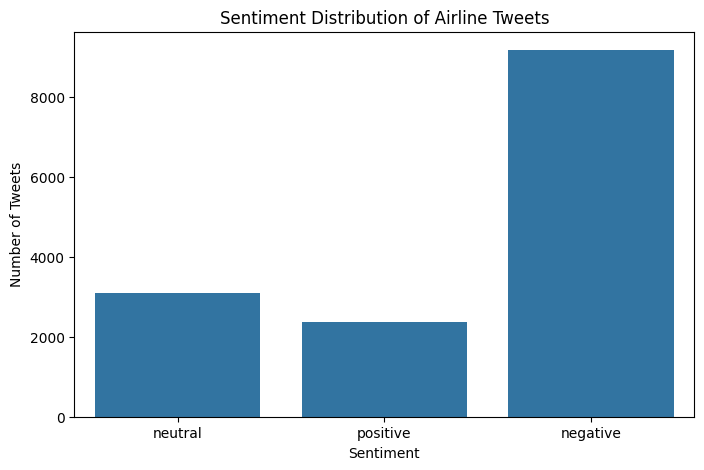

In [10]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x='airline_sentiment')

plt.title('Sentiment Distribution of Airline Tweets')
plt.xlabel('Sentiment')
plt.ylabel('Number of Tweets')

plt.show()

1. Negative sentiment has the highest number of tweets in the dataset.
2. Neutral sentiment has fewer tweets compared to negative sentiment.
3. Positive sentiment has the lowest number of tweets.
4. The dataset is imbalanced because the three sentiment categories do not have equal numbers of tweets.
5. This distribution indicates that customers expressed more negative opinions about airline services in this dataset.

In [11]:
!pip install nltk

In [12]:
import nltk
import re

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [13]:
stop_words = set(stopwords.words('english'))

# Preserve important negative words
stop_words = stop_words - {'not', 'no', 'nor'}

lemmatizer = WordNetLemmatizer()

def clean_text(text):

    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove usernames
    text = re.sub(r'@\w+', '', text)

    # Remove hashtag symbol
    text = re.sub(r'#', '', text)

    # Remove punctuation and numbers
    text = re.sub(r'[^a-z\s]', '', text)

    # Tokenization
    words = word_tokenize(text)

    # Stopword removal and lemmatization
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return ' '.join(words)

In [14]:
df['clean_text'] = df['text'].apply(clean_text)

In [15]:
df[['text', 'clean_text']].head(10)

,text,clean_text
0,@VirginAmerica What @dhepburn said.,said
1,@VirginAmerica plus you've added commercials t...,plus youve added commercial experience tacky
2,@VirginAmerica I didn't today... Must mean I n...,didnt today must mean need take another trip
3,@VirginAmerica it's really aggressive to blast...,really aggressive blast obnoxious entertainmen...
4,@VirginAmerica and it's a really big bad thing...,really big bad thing
5,@VirginAmerica seriously would pay $30 a fligh...,seriously would pay flight seat didnt playing ...
6,"@VirginAmerica yes, nearly every time I fly VX...",yes nearly every time fly vx ear worm wont go ...
7,@VirginAmerica Really missed a prime opportuni...,really missed prime opportunity men without ha...
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",well didntbut
9,"@VirginAmerica it was amazing, and arrived an ...",amazing arrived hour early youre good


All text was converted into lowercase.
URLs, usernames, punctuation and unnecessary numbers were removed.
Stopwords were removed to reduce unnecessary words.
Tokenization separated sentences into individual words.
Lemmatization converted words into their base forms.
The cleaned text is now more suitable for machine learning.

In [16]:
df[['text', 'clean_text']].head(10)

,text,clean_text
0,@VirginAmerica What @dhepburn said.,said
1,@VirginAmerica plus you've added commercials t...,plus youve added commercial experience tacky
2,@VirginAmerica I didn't today... Must mean I n...,didnt today must mean need take another trip
3,@VirginAmerica it's really aggressive to blast...,really aggressive blast obnoxious entertainmen...
4,@VirginAmerica and it's a really big bad thing...,really big bad thing
5,@VirginAmerica seriously would pay $30 a fligh...,seriously would pay flight seat didnt playing ...
6,"@VirginAmerica yes, nearly every time I fly VX...",yes nearly every time fly vx ear worm wont go ...
7,@VirginAmerica Really missed a prime opportuni...,really missed prime opportunity men without ha...
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",well didntbut
9,"@VirginAmerica it was amazing, and arrived an ...",amazing arrived hour early youre good


### TF-IDF Vectorization

TF-IDF (Term Frequency-Inverse Document Frequency) is a technique used to convert text data into numerical values that machine learning algorithms can understand.

It calculates the importance of each word based on how frequently it appears in a particular document and how rare it is across the entire collection of documents.

Common words receive lower importance, while more informative words receive higher importance.

In this project, TF-IDF is used to convert cleaned airline tweets into numerical features for sentiment classification.

In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [18]:
from sklearn.model_selection import train_test_split

X = df['clean_text']
y = df['airline_sentiment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [19]:
tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

In [20]:
print("Training data shape:", X_train_tfidf.shape)

print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (11712, 5000)
Testing data shape: (2928, 5000)


In [21]:
print("Number of features:", len(tfidf.get_feature_names_out()))

Number of features: 5000


The dataset was divided into 80% training data and 20% testing data.
Stratified splitting maintained the distribution of sentiment classes.
TF-IDF converted cleaned text into numerical features.
A maximum of 5,000 features was selected.
Training data was used to learn the vocabulary, while testing data was transformed using the same vocabulary.
The numerical features are now ready for machine learning classification

In [22]:
print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

(11712, 5000)
(2928, 5000)


In [23]:
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import accuracy_score, classification_report

In [24]:
nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

MultinomialNB()

In [25]:
y_pred_nb = nb_model.predict(X_test_tfidf)

In [26]:
print("Naive Bayes Accuracy:",
      accuracy_score(y_test, y_pred_nb))

print("\nClassification Report:\n")

print(classification_report(y_test, y_pred_nb))

Naive Bayes Accuracy: 0.7223360655737705

Classification Report:

              precision    recall  f1-score   support

    negative       0.71      0.99      0.83      1835
     neutral       0.75      0.23      0.35       620
    positive       0.87      0.33      0.48       473

    accuracy                           0.72      2928
   macro avg       0.78      0.52      0.55      2928
weighted avg       0.74      0.72      0.67      2928



In [27]:
from sklearn.linear_model import LogisticRegression

In [28]:
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000)

In [29]:
y_pred_lr = lr_model.predict(X_test_tfidf)

In [30]:
print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred_lr))

print("\nClassification Report:\n")

print(classification_report(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.7974726775956285

Classification Report:

              precision    recall  f1-score   support

    negative       0.82      0.95      0.88      1835
     neutral       0.67      0.54      0.60       620
    positive       0.82      0.57      0.67       473

    accuracy                           0.80      2928
   macro avg       0.77      0.68      0.72      2928
weighted avg       0.79      0.80      0.79      2928



In [31]:
nb_accuracy = accuracy_score(y_test, y_pred_nb)

lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("Naive Bayes Accuracy:", nb_accuracy * 100)

print("Logistic Regression Accuracy:", lr_accuracy * 100)

Naive Bayes Accuracy: 72.23360655737704
Logistic Regression Accuracy: 79.74726775956285


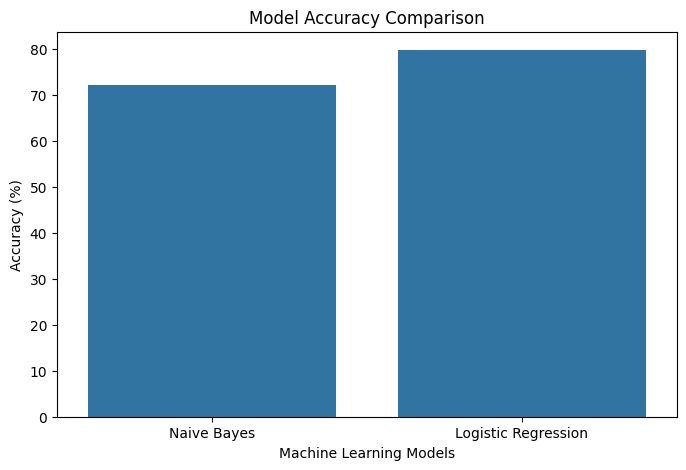

In [32]:
models = ['Naive Bayes', 'Logistic Regression']

accuracies = [nb_accuracy * 100, lr_accuracy * 100]

plt.figure(figsize=(8, 5))

sns.barplot(x=models, y=accuracies)

plt.title('Model Accuracy Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy (%)')

plt.show()

The accuracy comparison shows that Logistic Regression achieved approximately 80% accuracy, while Naive Bayes achieved approximately 72%. Therefore, Logistic Regression performed better in predicting the sentiment of airline tweets compared to Naive Bayes.

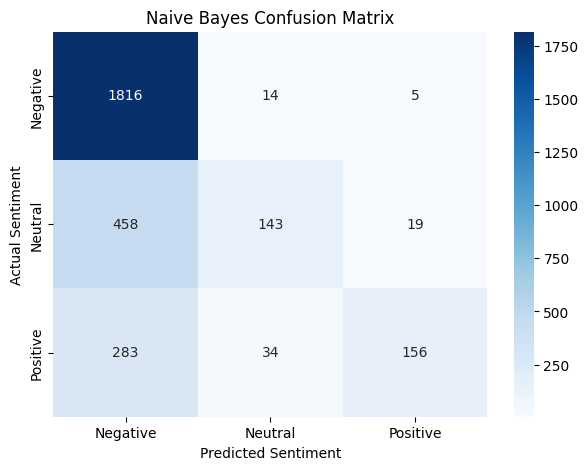

In [33]:
from sklearn.metrics import confusion_matrix

cm_nb = confusion_matrix(
    y_test, y_pred_nb,
    labels=['negative', 'neutral', 'positive']
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_nb,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.title('Naive Bayes Confusion Matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.show()

Negative Sentiment: The model correctly classified 1816 negative tweets. Only a small number were incorrectly classified as neutral or positive.
Neutral Sentiment: The model correctly identified 143 neutral tweets, but 458 neutral tweets were incorrectly classified as negative.
Positive Sentiment: The model correctly classified 156 positive tweets, while 283 positive tweets were incorrectly predicted as negative.
Overall Performance: The model performs well in identifying negative tweets but struggles to distinguish neutral and positive tweets.

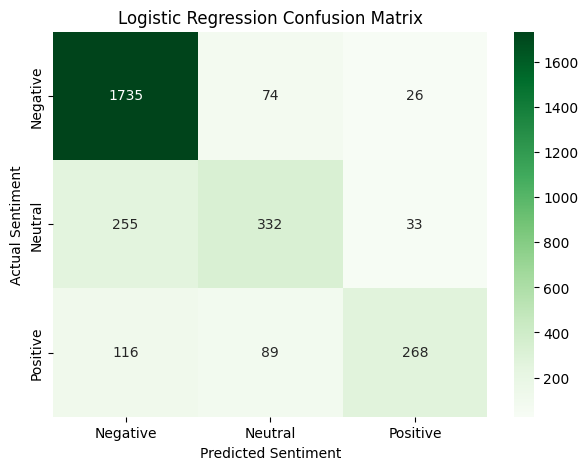

In [34]:
cm_lr = confusion_matrix(
    y_test, y_pred_lr,
    labels=['negative', 'neutral', 'positive']
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Negative', 'Neutral', 'Positive'],
    yticklabels=['Negative', 'Neutral', 'Positive']
)

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.show()

The Logistic Regression model correctly classified 1,735 negative, 332 neutral, and 268 positive sentiments.
The model performs very well in predicting Negative sentiment.
It has moderate performance in predicting Neutral and Positive sentiments.
Many neutral reviews (255) were incorrectly classified as negative.
Some positive reviews were also misclassified as negative (116) or neutral (89).
The overall accuracy of the model is approximately 79.75%.

In [35]:
!pip install wordcloud

In [36]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

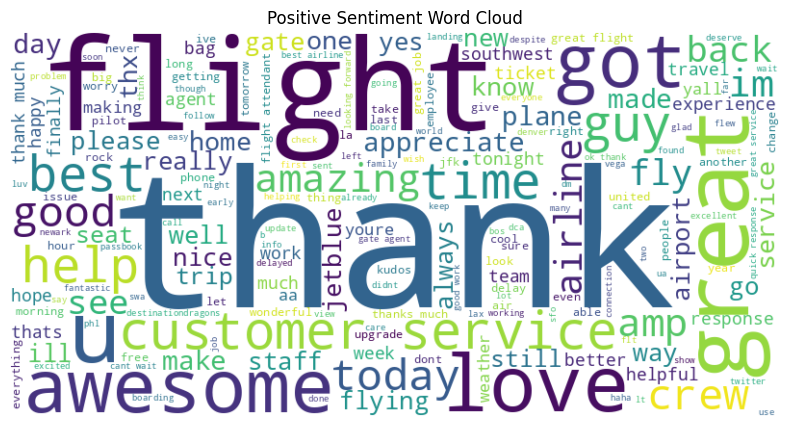

In [40]:
positive_text = ' '.join(df[df['airline_sentiment'] == 'positive']['cleaned_text'])

wordcloud = WordCloud(width=800, height=400, background_color='white').generate(positive_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Positive Sentiment Word Cloud')
plt.show()

The word cloud represents the most frequently used words in positive tweets. Words appearing larger in size occur more frequently. It helps identify common words and expressions associated with positive customer feedback about airlines.

In [38]:
df.columns


Index(['tweet_id', 'airline_sentiment', 'airline_sentiment_confidence',
       'negativereason', 'negativereason_confidence', 'airline',
       'airline_sentiment_gold', 'name', 'negativereason_gold',
       'retweet_count', 'text', 'tweet_coord', 'tweet_created',
       'tweet_location', 'user_timezone', 'clean_text'],
      dtype='object')

In [39]:
df['cleaned_text'] = df['text'].apply(clean_text)

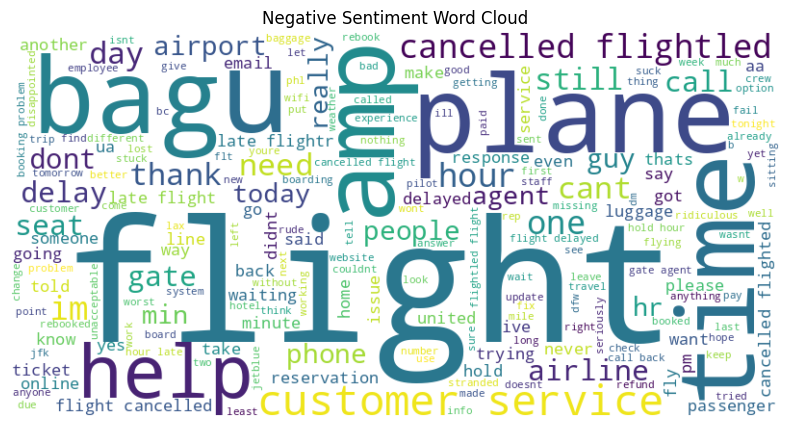

In [41]:
negative_text = ' '.join(df[df['airline_sentiment'] == 'negative']['cleaned_text'])

wordcloud = WordCloud(width=800, height=400, background_color='white').generate(negative_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Negative Sentiment Word Cloud')
plt.show()

The word cloud represents the most frequently used words in positive tweets. Larger words indicate higher frequency. It helps identify commonly used words and expressions in positive customer feedback about airlines.

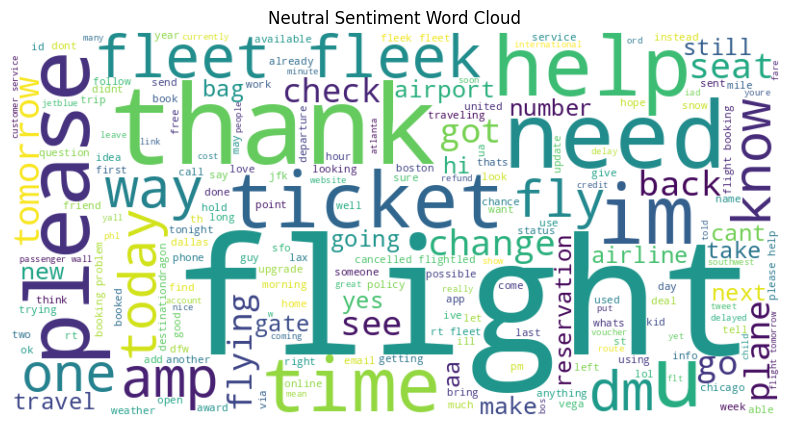

In [42]:
neutral_text = ' '.join(df[df['airline_sentiment'] == 'neutral']['cleaned_text'])

wordcloud = WordCloud(width=800, height=400, background_color='white').generate(neutral_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Neutral Sentiment Word Cloud')
plt.show()

The word cloud displays the most frequently used words in neutral tweets. Larger words represent words that appear more often in customer feedback. It helps identify common topics and expressions used in neutral airline reviews.

In [43]:
results = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred_lr
})

incorrect_predictions = results[results['Actual'] != results['Predicted']]

incorrect_predictions.head(5)

,Actual,Predicted
2998,neutral,negative
7719,positive,negative
4006,neutral,negative
4686,negative,neutral
8985,positive,negative


In [44]:
from sklearn.metrics import accuracy_score

In [45]:
nb_accuracy = accuracy_score(y_test, y_pred_nb)

lr_accuracy = accuracy_score(y_test, y_pred_lr)

print("Naive Bayes Accuracy:", nb_accuracy * 100)
print("Logistic Regression Accuracy:", lr_accuracy * 100)

Naive Bayes Accuracy: 72.23360655737704
Logistic Regression Accuracy: 79.74726775956285


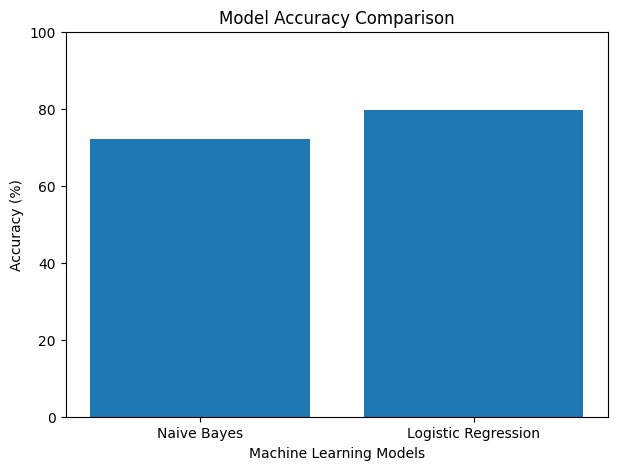

In [46]:
models = ['Naive Bayes', 'Logistic Regression']
accuracies = [nb_accuracy * 100, lr_accuracy * 100]

plt.figure(figsize=(7, 5))
plt.bar(models, accuracies)

plt.title('Model Accuracy Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)

plt.show()

The accuracy comparison shows that Logistic Regression achieved higher accuracy than Naive Bayes. This indicates that Logistic Regression performed better in classifying airline tweets into positive, negative, and neutral sentiments.

Conclusion: Among the two machine learning algorithms, Logistic Regression provided better classification performance and was the more effective model for this sentiment analysis task.

### Conclusion

In this task, sentiment analysis was performed on airline customer tweets to identify positive, negative, and neutral opinions.

The dataset was explored and cleaned using text preprocessing techniques such as removing special characters, URLs, stopwords, and applying stemming.

Word Cloud visualizations were created to understand frequently used words in different sentiment categories.

Two machine learning algorithms, Naive Bayes and Logistic Regression, were implemented and evaluated using confusion matrices and accuracy scores.

The results showed that Logistic Regression achieved higher accuracy than Naive Bayes. Therefore, Logistic Regression performed better on this dataset.

Overall, this task helped in understanding text preprocessing, sentiment classification, model evaluation, and customer feedback analysis using machine learning.